In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [4]:
train_dir = '/kaggle/input/ecg-analysis/ECG_DATA/train'
test_dir = '/kaggle/input/ecg-analysis/ECG_DATA/test'

In [5]:
import os

In [10]:
def get_subfolders_and_image_counts(directory):
    subfolders = {}
    for subdir, dirs, files in os.walk(directory):
        if dirs:
            for folder in dirs:
                folder_path = os.path.join(subdir, folder)
                num_images = len([file for file in os.listdir(folder_path) if file.endswith(('.png', '.jpg', '.jpeg'))])
                subfolders[folder] = num_images
    return subfolders

train_subfolders = get_subfolders_and_image_counts(train_dir)
test_subfolders = get_subfolders_and_image_counts(test_dir)

In [11]:
print("Training Subfolders and Image Counts:")
for folder, count in train_subfolders.items():
    print(f"{folder}: {count} images")

print("\nTest Subfolders and Image Counts:")
for folder, count in test_subfolders.items():
    print(f"{folder}: {count} images")

Training Subfolders and Image Counts:
ECG Images of Patient that have abnormal heartbeat (233x12=2796): 699 images
ECG Images of Patient that have History of MI (172x12=2064): 516 images
Normal Person ECG Images (284x12=3408): 852 images
ECG Images of Myocardial Infarction Patients (240x12=2880): 956 images

Test Subfolders and Image Counts:
ECG Images of Patient that have abnormal heartbeat (233x12=2796): 233 images
ECG Images of Patient that have History of MI (172x12=2064): 172 images
Normal Person ECG Images (284x12=3408): 284 images
ECG Images of Myocardial Infarction Patients (240x12=2880): 239 images


In [12]:
def plot_images_from_subfolders(directory, subfolders):
    for folder in subfolders:
        folder_path = os.path.join(directory, folder)
        image_files = [file for file in os.listdir(folder_path) if file.endswith(('.png', '.jpg', '.jpeg'))][:10]  # Get 10 images
        print(f"\nShowing 10 images from {folder}:")

        plt.figure(figsize=(20, 10))
        for i, image_file in enumerate(image_files):
            img_path = os.path.join(folder_path, image_file)
            img = mpimg.imread(img_path)
            plt.subplot(2, 5, i+1)
            plt.imshow(img)
            plt.axis('off')  

        plt.show()

In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

2025-09-09 05:05:10.442712: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1757394310.783606      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1757394310.876454      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered



Showing 10 images from ECG Images of Patient that have abnormal heartbeat (233x12=2796):


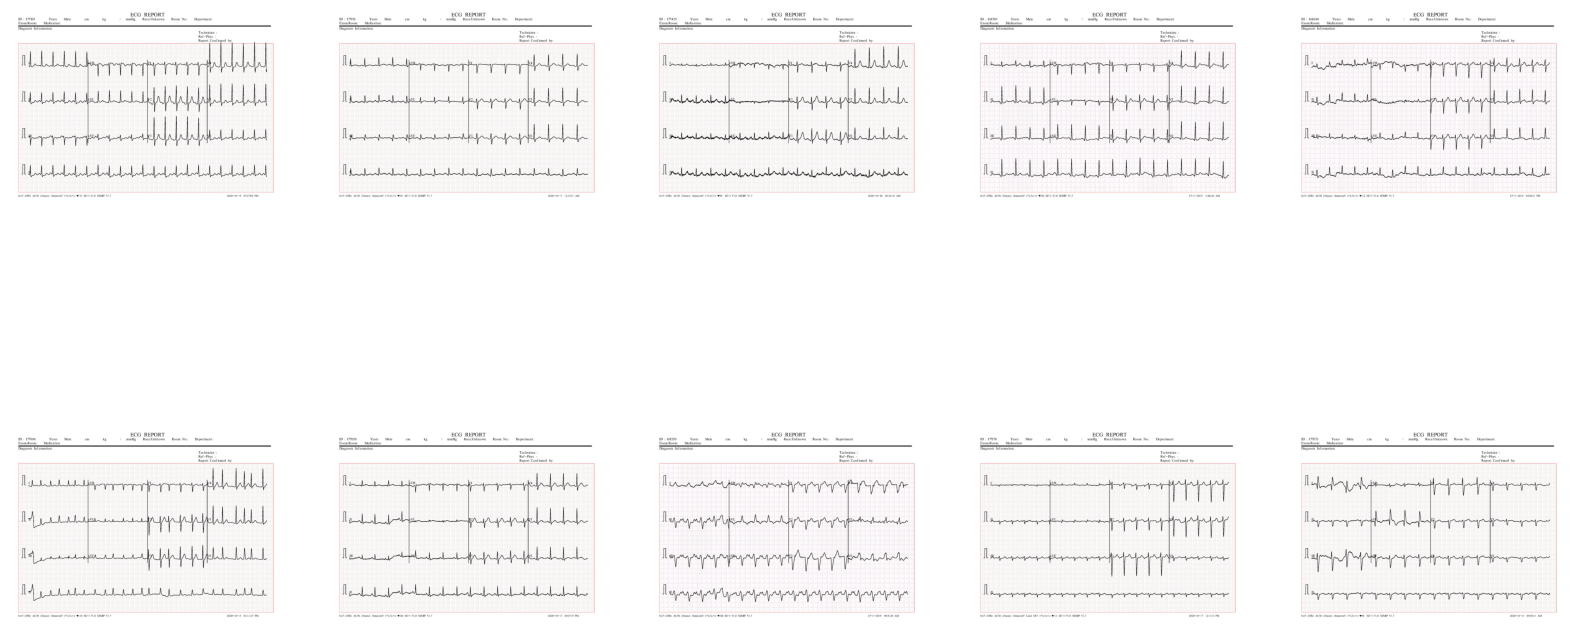


Showing 10 images from ECG Images of Patient that have History of MI (172x12=2064):


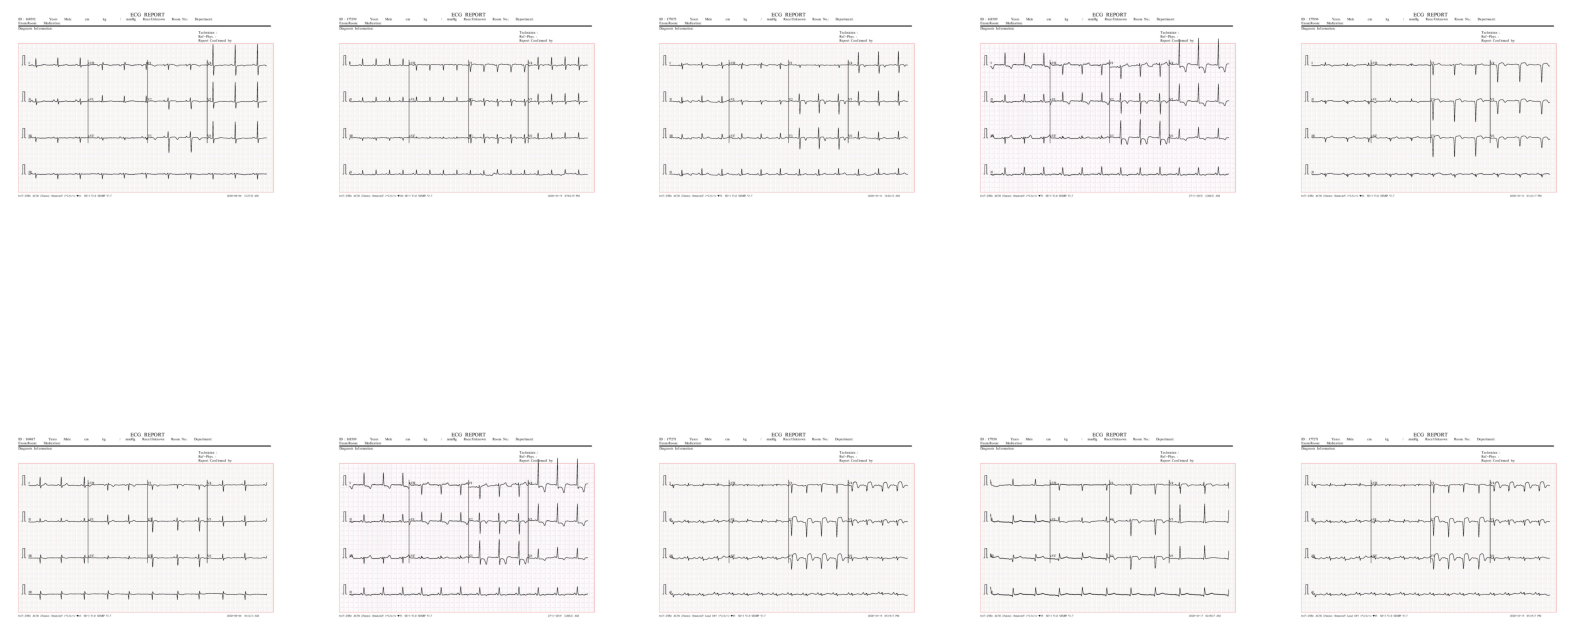


Showing 10 images from Normal Person ECG Images (284x12=3408):


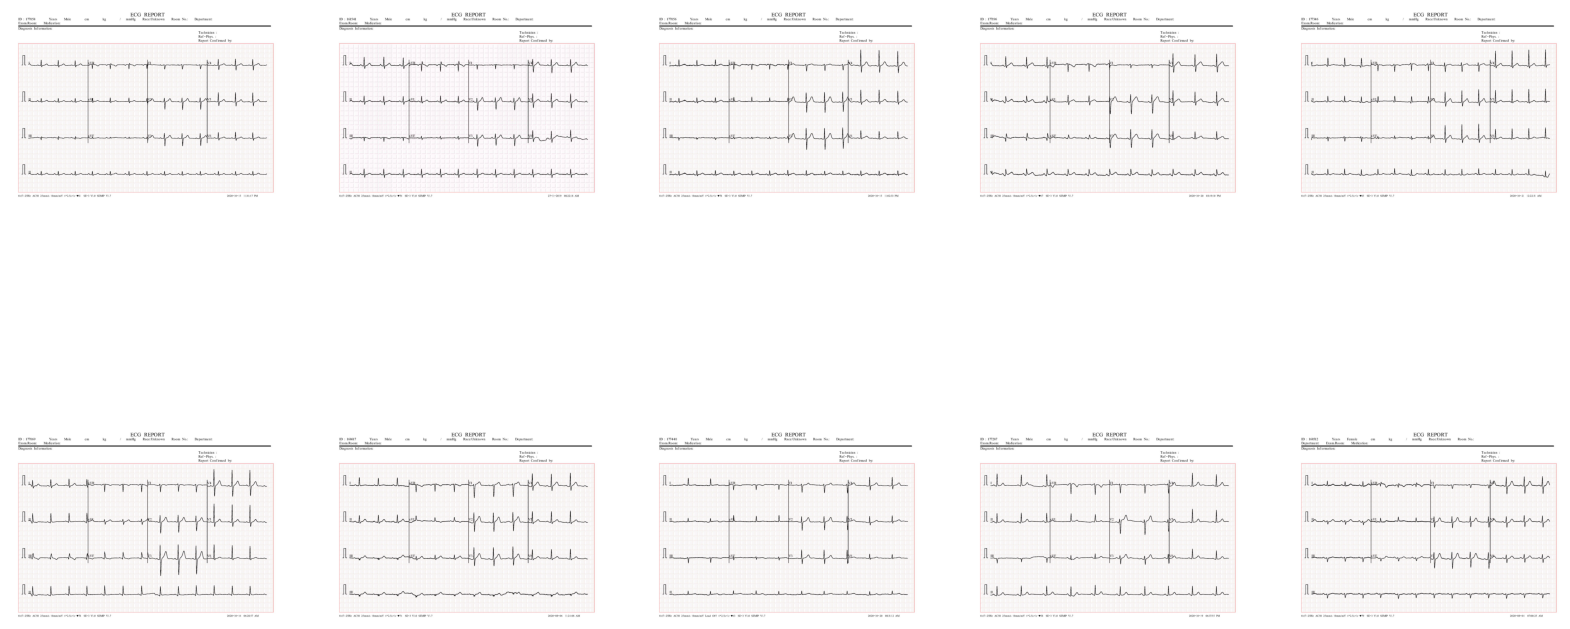


Showing 10 images from ECG Images of Myocardial Infarction Patients (240x12=2880):


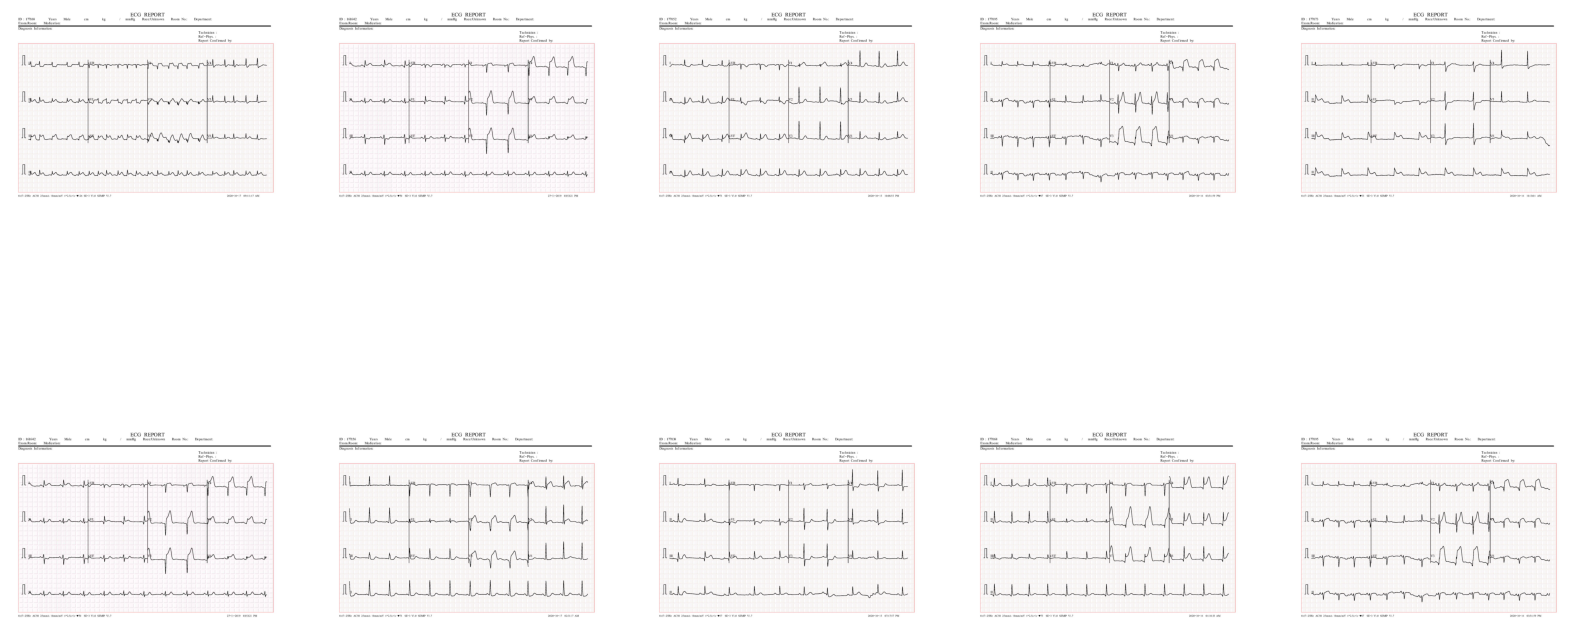

In [14]:
plot_images_from_subfolders(train_dir, train_subfolders)

In [15]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2  
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),  
    batch_size=32,
    class_mode='categorical',
    subset='training'  
)

validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'  
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

print("Class indices:", train_generator.class_indices)

Found 2420 images belonging to 4 classes.
Found 603 images belonging to 4 classes.
Found 928 images belonging to 4 classes.
Class indices: {'ECG Images of Myocardial Infarction Patients (240x12=2880)': 0, 'ECG Images of Patient that have History of MI (172x12=2064)': 1, 'ECG Images of Patient that have abnormal heartbeat (233x12=2796)': 2, 'Normal Person ECG Images (284x12=3408)': 3}


In [18]:
import tensorflow as tf

In [20]:
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPUs are available and memory growth is set.")
    except RuntimeError as e:
        print(e)

GPUs are available and memory growth is set.


In [23]:
from tensorflow.keras import layers, models

# **Convolutional Neural Network**

In [18]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(train_generator.class_indices), activation='softmax')  
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1757192267.542273      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1757192267.542990      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [19]:
!pip install keras-tuner

# **Hyperparameter tuning with Keras Tuner**

In [36]:
from kerastuner.tuners import RandomSearch
from tensorflow.keras import layers, models, optimizers
import tensorflow as tf

def build_custom_model(hp):
    model = models.Sequential()
    model.add(layers.Conv2D(hp.Int('conv1_filters', 32, 128, step=32), (3, 3), activation='relu', input_shape=(224, 224, 3)))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(hp.Int('conv2_filters', 64, 128, step=32), (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(hp.Int('dense_units', 64, 256, step=64), activation='relu'))
    model.add(layers.Dense(len(train_generator.class_indices), activation='softmax'))

    model.compile(
        optimizer=optimizers.Adam(hp.Choice('learning_rate', [1e-2, 1e-3, 1e-4])),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

tuner = RandomSearch(
    build_custom_model,
    objective='val_accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='cnn_tuning',
    project_name='custom_cnn'
)

tuner.search(train_generator, validation_data=validation_generator, epochs=10)
best_model = tuner.get_best_models(num_models=1)[0]

Trial 10 Complete [00h 09m 39s]
val_accuracy: 0.31674957275390625

Best val_accuracy So Far: 1.0
Total elapsed time: 01h 41m 43s


/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [39]:
from kerastuner.tuners import RandomSearch
from tensorflow.keras import layers, models, optimizers
import tensorflow as tf

def build_custom_model(hp):
    model = models.Sequential()
    model.add(layers.Conv2D(hp.Int('conv1_filters', 32, 128, step=32), (3, 3), activation='relu', input_shape=(224, 224, 3)))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(hp.Int('conv2_filters', 64, 128, step=32), (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(hp.Int('dense_units', 64, 256, step=64), activation='relu'))
    model.add(layers.Dense(len(train_generator.class_indices), activation='softmax'))

    model.compile(
        optimizer=optimizers.Adam(hp.Choice('learning_rate', [1e-2, 1e-3, 1e-4])),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

tuner = RandomSearch(
    build_custom_model,
    objective='val_accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='cnn_tuning',
    project_name='custom_cnn'
)

tuner.search(train_generator, validation_data=validation_generator, epochs=10)
best_model = tuner.get_best_models(num_models=1)[0]

Reloading Tuner from cnn_tuning/custom_cnn/tuner0.json


In [41]:
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    47,776,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,815,748 (182.40 MB)

 Trainable params: 47,815,748 (182.40 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
from itertools import cycle

# Fit the model
history = best_model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    epochs=10
)

Epoch 1/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 61s 788ms/step - accuracy: 0.9816 - loss: 0.0573 - val_accuracy: 0.9965 - val_loss: 0.0098
Epoch 2/10
 1/75 ━━━━━━━━━━━━━━━━━━━━ 5s 79ms/step - accuracy: 0.9688 - loss: 0.0368

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


75/75 ━━━━━━━━━━━━━━━━━━━━ 12s 162ms/step - accuracy: 0.9688 - loss: 0.0368 - val_accuracy: 1.0000 - val_loss: 0.0032
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 57s 753ms/step - accuracy: 0.9987 - loss: 0.0078 - val_accuracy: 1.0000 - val_loss: 9.6758e-04
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 11s 148ms/step - accuracy: 1.0000 - loss: 8.0254e-04 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 56s 750ms/step - accuracy: 1.0000 - loss: 4.0607e-04 - val_accuracy: 1.0000 - val_loss: 2.5674e-04
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 12s 162ms/step - accuracy: 1.0000 - loss: 1.9148e-04 - val_accuracy: 1.0000 - val_loss: 2.4841e-04
Epoch 7/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 56s 754ms/step - accuracy: 1.0000 - loss: 1.4220e-04 - val_accuracy: 1.0000 - val_loss: 1.6894e-04
Epoch 8/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 12s 156ms/step - accuracy: 1.0000 - loss: 2.2683e-04 - val_accuracy: 1.0000 - val_loss: 1.6637e-04
Epoch 9/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 58s 774ms/step - accuracy: 1.0

29/29 ━━━━━━━━━━━━━━━━━━━━ 28s 971ms/step - accuracy: 1.0000 - loss: 1.0453e-04

Test Accuracy: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━

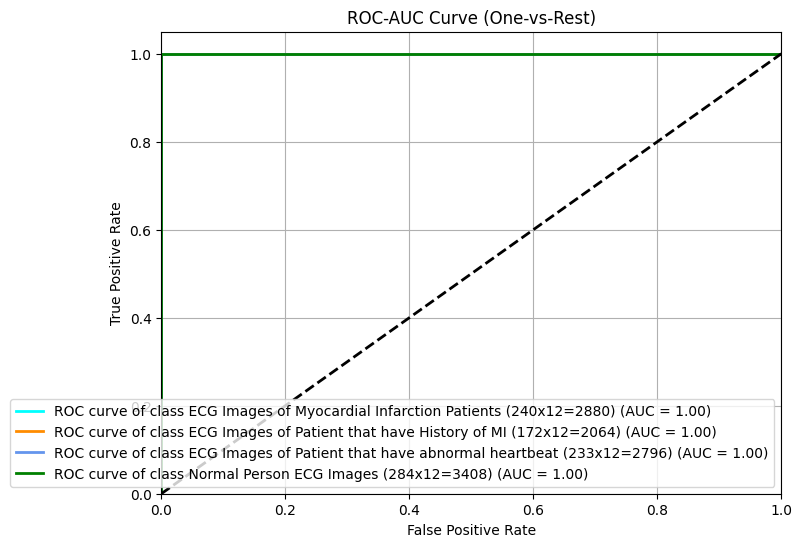

In [43]:
# Evaluate the model on the test set
test_loss, test_acc = best_model.evaluate(test_generator)
print(f"\nTest Accuracy: {test_acc:.4f}")

# Get class labels from the generator
class_labels = list(test_generator.class_indices.keys())
num_classes = len(class_labels)

# Reset test_generator to ensure consistent iteration
test_generator.reset()

# Get true labels and predictions
y_true = []
y_pred_prob = []
for i in range(test_generator.samples // test_generator.batch_size):
    batch_x, batch_y = next(test_generator)
    y_true.append(batch_y)
    y_pred_prob.append(best_model.predict(batch_x))

# Concatenate all batches
y_true = np.concatenate(y_true, axis=0)
y_pred_prob = np.concatenate(y_pred_prob, axis=0)

# Convert one-hot encoded labels to class indices
y_true_classes = np.argmax(y_true, axis=1)
y_pred_classes = np.argmax(y_pred_prob, axis=1)

# Compute Precision, Recall, and F1 Score (macro-averaged for multi-class)
precision = precision_score(y_true_classes, y_pred_classes, average='macro')
recall = recall_score(y_true_classes, y_pred_classes, average='macro')
f1 = f1_score(y_true_classes, y_pred_classes, average='macro')

print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1 Score (macro): {f1:.4f}")

# Compute Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
print("\nConfusion Matrix:")
print(cm)

# Compute TPR, TNR, FPR, FNR per class
def compute_rates(conf_matrix, num_classes):
    tpr = []
    tnr = []
    fpr = []
    fnr = []
    for i in range(num_classes):
        tp = conf_matrix[i, i]
        fn = np.sum(conf_matrix[i, :]) - tp
        fp = np.sum(conf_matrix[:, i]) - tp
        tn = np.sum(conf_matrix) - (tp + fn + fp)
        
        tpr_i = tp / (tp + fn) if (tp + fn) > 0 else 0
        tnr_i = tn / (tn + fp) if (tn + fp) > 0 else 0
        fpr_i = fp / (fp + tn) if (fp + tn) > 0 else 0
        fnr_i = fn / (fn + tp) if (fn + tp) > 0 else 0
        
        tpr.append(tpr_i)
        tnr.append(tnr_i)
        fpr.append(fpr_i)
        fnr.append(fnr_i)
    
    return tpr, tnr, fpr, fnr

tpr, tnr, fpr, fnr = compute_rates(cm, num_classes)
print("\nPer-class Metrics:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}':")
    print(f"  TPR (Recall): {tpr[i]:.4f}")
    print(f"  TNR: {tnr[i]:.4f}")
    print(f"  FPR: {fpr[i]:.4f}")
    print(f"  FNR: {fnr[i]:.4f}")

# Compute AUC for each class (One-vs-Rest)
fpr_roc = {}
tpr_roc = {}
roc_auc = {}
for i in range(num_classes):
    fpr_roc[i], tpr_roc[i], _ = roc_curve(y_true[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr_roc[i], tpr_roc[i])
print("\nAUC per class:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}': AUC = {roc_auc[i]:.4f}")

# Plot ROC-AUC Curve
plt.figure(figsize=(8, 6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple', 'brown', 'pink', 'gray', 'olive'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr_roc[i], tpr_roc[i], color=color, lw=2,
             label=f'ROC curve of class {class_labels[i]} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

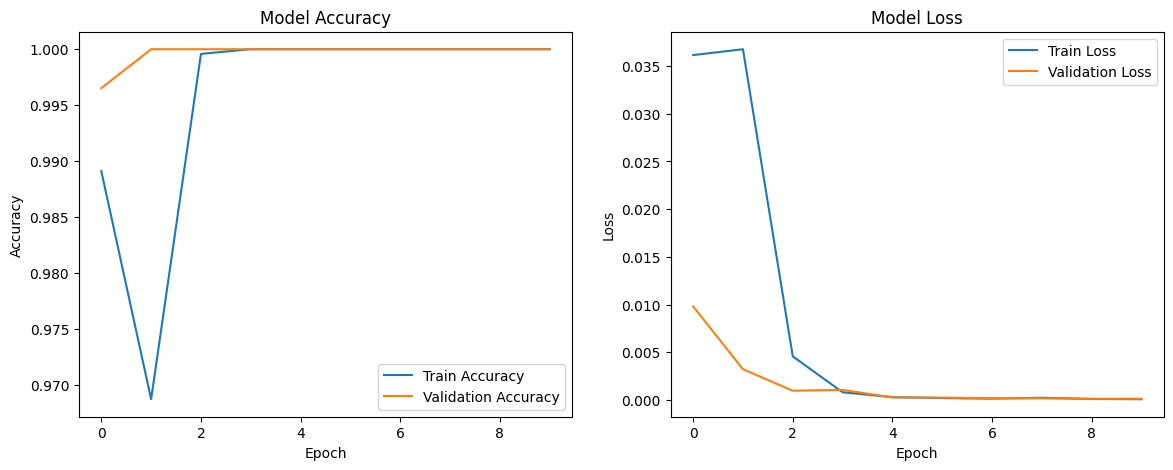

In [44]:
def plot_training_history(history):
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

plot_training_history(history)


AUC per class:
Class 'Myocardial Infarction (MI)': AUC = 1.0000
Class 'History of MI': AUC = 1.0000
Class 'Abnormal Heartbeat': AUC = 1.0000
Class 'Normal': AUC = 1.0000


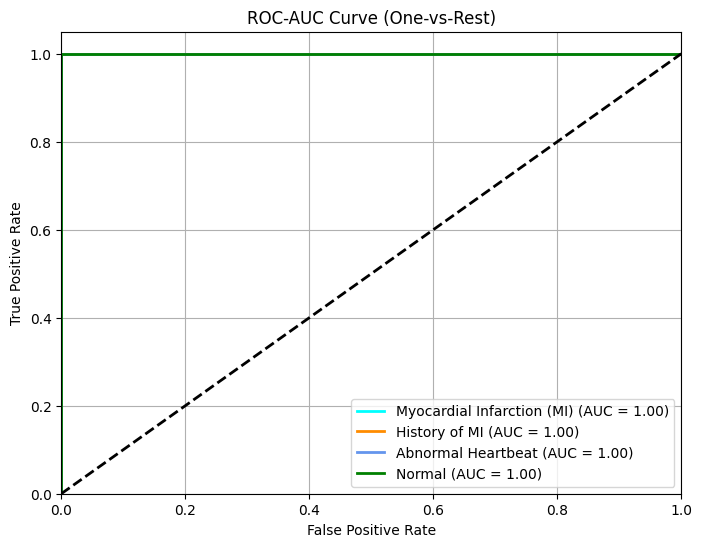

In [45]:
# Define shortened class labels
class_labels = ["Myocardial Infarction (MI)", "History of MI", "Abnormal Heartbeat", "Normal"]

# Compute AUC for each class (One-vs-Rest)
fpr_roc = {}
tpr_roc = {}
roc_auc = {}
for i in range(num_classes):
    fpr_roc[i], tpr_roc[i], _ = roc_curve(y_true[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr_roc[i], tpr_roc[i])

print("\nAUC per class:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}': AUC = {roc_auc[i]:.4f}")

# Plot ROC-AUC Curve
plt.figure(figsize=(8, 6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr_roc[i], tpr_roc[i], color=color, lw=2,
             label=f'{class_labels[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [27]:
from tensorflow.keras.applications import VGG16

# **VGG16**

In [31]:
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

In [34]:
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(train_generator.class_indices), activation='softmax')  
])

In [38]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# **Hyperparameter tuning with Keras Tuner**

In [ ]:
from kerastuner.tuners import RandomSearch
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models, optimizers
import tensorflow as tf

def build_vgg16_model(hp):
    # Load base VGG16 model
    base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False  # Freeze convolutional base

    model = models.Sequential()
    model.add(base_model)
    model.add(layers.Flatten())

    # Tune dense layer size
    model.add(layers.Dense(
        hp.Int('dense_units', min_value=64, max_value=256, step=64),
        activation='relu'
    ))

    # Optional dropout
    model.add(layers.Dropout(
        hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1)
    ))

    # Final output layer
    model.add(layers.Dense(len(train_generator.class_indices), activation='softmax'))

    # Compile with tunable learning rate
    model.compile(
        optimizer=optimizers.Adam(
            hp.Choice('learning_rate', [1e-2, 1e-3, 1e-4])
        ),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

tuner = RandomSearch(
    build_vgg16_model,
    objective='val_accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='vgg16_tuning',
    project_name='vgg16_transfer_learning'
)

tuner.search(train_generator, validation_data=validation_generator, epochs=10)

# Get the best model
best_model = tuner.get_best_models(num_models=1)[0]



In [ ]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [99]:
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,751,438 (10.50 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 328,970 (1.25 MB)

In [ ]:
history = best_model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    epochs=10
)

Epoch 1/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 57s 767ms/step - accuracy: 0.9108 - loss: 0.2348 - val_accuracy: 0.9497 - val_loss: 0.1404
Epoch 2/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 12s 162ms/step - accuracy: 0.9375 - loss: 0.1034 - val_accuracy: 0.9045 - val_loss: 0.1931
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 56s 750ms/step - accuracy: 0.9063 - loss: 0.2453 - val_accuracy: 0.9219 - val_loss: 0.1918
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 11s 154ms/step - accuracy: 0.8438 - loss: 0.5241 - val_accuracy: 0.9201 - val_loss: 0.1734
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 64s 848ms/step - accuracy: 0.9168 - loss: 0.2025 - val_accuracy: 0.9688 - val_loss: 0.1024
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 12s 159ms/step - accuracy: 0.9375 - loss: 0.1917 - val_accuracy: 0.9722 - val_loss: 0.1092
Epoch 7/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 57s 762ms/step - accuracy: 0.9303 - loss: 0.1812 - val_accuracy: 0.9757 - val_loss: 0.0829
Epoch 8/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 11s 149ms/step - accuracy: 0.9375 - loss: 0.2306 - val_accu

In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
from itertools import cycle

# Fit the model

# Evaluate the model on the test set
test_loss, test_acc = best_model.evaluate(test_generator)
print(f"\nTest Accuracy: {test_acc:.4f}")

# Get class labels from the generator
class_labels = list(test_generator.class_indices.keys())
num_classes = len(class_labels)

# Reset test_generator to ensure consistent iteration
test_generator.reset()

# Get true labels and predictions
y_true = []
y_pred_prob = []
for i in range(test_generator.samples // test_generator.batch_size):
    batch_x, batch_y = next(test_generator)
    y_true.append(batch_y)
    y_pred_prob.append(best_model.predict(batch_x))

# Concatenate all batches
y_true = np.concatenate(y_true, axis=0)
y_pred_prob = np.concatenate(y_pred_prob, axis=0)

# Convert one-hot encoded labels to class indices
y_true_classes = np.argmax(y_true, axis=1)
y_pred_classes = np.argmax(y_pred_prob, axis=1)

# Compute Precision, Recall, and F1 Score (macro-averaged for multi-class)
precision = precision_score(y_true_classes, y_pred_classes, average='macro')
recall = recall_score(y_true_classes, y_pred_classes, average='macro')
f1 = f1_score(y_true_classes, y_pred_classes, average='macro')

print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1 Score (macro): {f1:.4f}")

# Compute Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
print("\nConfusion Matrix:")
print(cm)

# Compute TPR, TNR, FPR, FNR per class
def compute_rates(conf_matrix, num_classes):
    tpr = []
    tnr = []
    fpr = []
    fnr = []
    for i in range(num_classes):
        tp = conf_matrix[i, i]
        fn = np.sum(conf_matrix[i, :]) - tp
        fp = np.sum(conf_matrix[:, i]) - tp
        tn = np.sum(conf_matrix) - (tp + fn + fp)
        
        tpr_i = tp / (tp + fn) if (tp + fn) > 0 else 0
        tnr_i = tn / (tn + fp) if (tn + fp) > 0 else 0
        fpr_i = fp / (fp + tn) if (fp + tn) > 0 else 0
        fnr_i = fn / (fn + tp) if (fn + tp) > 0 else 0
        
        tpr.append(tpr_i)
        tnr.append(tnr_i)
        fpr.append(fpr_i)
        fnr.append(fnr_i)
    
    return tpr, tnr, fpr, fnr

tpr, tnr, fpr, fnr = compute_rates(cm, num_classes)
print("\nPer-class Metrics:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}':")
    print(f"  TPR (Recall): {tpr[i]:.4f}")
    print(f"  TNR: {tnr[i]:.4f}")
    print(f"  FPR: {fpr[i]:.4f}")
    print(f"  FNR: {fnr[i]:.4f}")

# Compute AUC for each class (One-vs-Rest)
fpr_roc = {}
tpr_roc = {}
roc_auc = {}
for i in range(num_classes):
    fpr_roc[i], tpr_roc[i], _ = roc_curve(y_true[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr_roc[i], tpr_roc[i])
print("\nAUC per class:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}': AUC = {roc_auc[i]:.4f}")

# Plot ROC-AUC Curve
plt.figure(figsize=(8, 6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple', 'brown', 'pink', 'gray', 'olive'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr_roc[i], tpr_roc[i], color=color, lw=2,
             label=f'ROC curve of class {class_labels[i]} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [101]:
test_loss, test_acc =best_model.evaluate(test_generator)
print(f"\nTest Accuracy: {test_acc}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 18s 621ms/step - accuracy: 0.9839 - loss: 0.0801

Test Accuracy: 0.9795258641242981


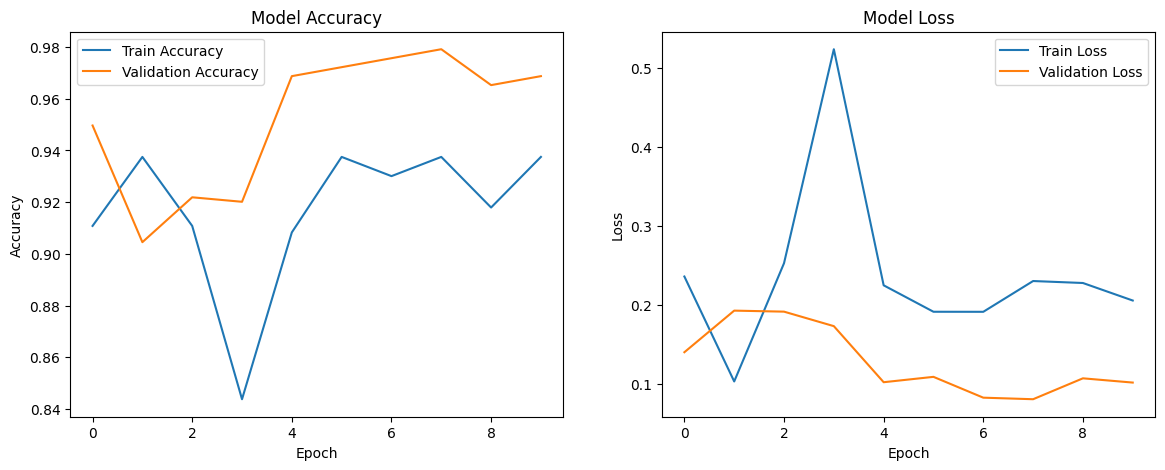

In [113]:
def plot_training_history(history):
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

plot_training_history(history)

# **InceptionV3**

In [48]:
import numpy as np

In [49]:
# test_generator.reset()
# predictions = model.predict(test_generator, steps=test_generator.samples // test_generator.batch_size + 1)
# predicted_classes = np.argmax(predictions, axis=1)
# true_classes = test_generator.classes
# class_labels = list(test_generator.class_indices.keys())

In [50]:
import seaborn as sns

In [54]:
# from tensorflow.keras.applications import InceptionV3, ResNet50, MobileNetV2
# from tensorflow.keras import models, layers

# # Assuming train_generator, validation_generator, test_generator are already defined as in the notebook

# # InceptionV3
# base_model_inception = InceptionV3(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
# base_model_inception.trainable = False

# model_inception = models.Sequential([
#     base_model_inception,
#     layers.Flatten(),
#     layers.Dense(128, activation='relu'),
#     layers.Dense(len(train_generator.class_indices), activation='softmax')
# ])

# model_inception.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# history_inception = model_inception.fit(
#     train_generator,
#     steps_per_epoch=train_generator.samples // train_generator.batch_size,
#     validation_data=validation_generator,
#     validation_steps=validation_generator.samples // validation_generator.batch_size,
#     epochs=10
# )

# test_loss_inception, test_acc_inception = model_inception.evaluate(test_generator)
# print(f"InceptionV3 Test Accuracy: {test_acc_inception}")


# **Hyperparameter tuning with Keras Tuner**

In [57]:
from kerastuner.tuners import RandomSearch
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf

# Assuming you have train_generator and validation_generator already defined
# Example setup (optional - customize your paths accordingly):
# train_generator = ...
# validation_generator = ...

def build_inception_model(hp):
    base_model = InceptionV3(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
    base_model.trainable = False  # You can change to True for fine-tuning
    
    model = models.Sequential()
    model.add(base_model)
    model.add(layers.GlobalAveragePooling2D())
    
    # Tune the number of units in the dense layer
    model.add(layers.Dense(hp.Int('dense_units', min_value=64, max_value=256, step=64), activation='relu'))
    
    # Tune dropout rate
    model.add(layers.Dropout(hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1)))
    
    model.add(layers.Dense(len(train_generator.class_indices), activation='softmax'))
    
    model.compile(
        optimizer=optimizers.Adam(
            hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
        ),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    return model

# Create the tuner
tuner = RandomSearch(
    build_inception_model,
    objective='val_accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='inceptionv3_tuning',
    project_name='inceptionv3_hyperparam'
)

# Perform hyperparameter search
tuner.search(train_generator, validation_data=validation_generator, epochs=10)

# Get the best model
best_model = tuner.get_best_models(num_models=1)[0]


Trial 10 Complete [00h 10m 31s]
val_accuracy: 0.8159204125404358

Best val_accuracy So Far: 0.8540630340576172
Total elapsed time: 01h 45m 43s


/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [59]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [61]:
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,934,180 (83.67 MB)

 Trainable params: 131,396 (513.27 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [62]:
history = best_model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    epochs=10  
)

Epoch 1/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 77s 833ms/step - accuracy: 0.7493 - loss: 0.6352 - val_accuracy: 0.8681 - val_loss: 0.4173
Epoch 2/10
 1/75 ━━━━━━━━━━━━━━━━━━━━ 4:57 4s/step - accuracy: 0.9500 - loss: 0.5205

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


75/75 ━━━━━━━━━━━━━━━━━━━━ 15s 151ms/step - accuracy: 0.9500 - loss: 0.5205 - val_accuracy: 0.8524 - val_loss: 0.4133
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 57s 760ms/step - accuracy: 0.7863 - loss: 0.5572 - val_accuracy: 0.8628 - val_loss: 0.4016
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 13s 168ms/step - accuracy: 0.7812 - loss: 0.3946 - val_accuracy: 0.8611 - val_loss: 0.4000
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 58s 765ms/step - accuracy: 0.7930 - loss: 0.5449 - val_accuracy: 0.8976 - val_loss: 0.4074
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 13s 176ms/step - accuracy: 0.8750 - loss: 0.4382 - val_accuracy: 0.8906 - val_loss: 0.4010
Epoch 7/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 58s 770ms/step - accuracy: 0.8001 - loss: 0.5203 - val_accuracy: 0.8594 - val_loss: 0.3700
Epoch 8/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 11s 154ms/step - accuracy: 0.7500 - loss: 0.6046 - val_accuracy: 0.8576 - val_loss: 0.3826
Epoch 9/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 57s 759ms/step - accuracy: 0.8248 - loss: 0.4527 - val_accuracy: 0.871

29/29 ━━━━━━━━━━━━━━━━━━━━ 18s 614ms/step - accuracy: 0.8894 - loss: 0.3369

Test Accuracy: 0.8869
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━

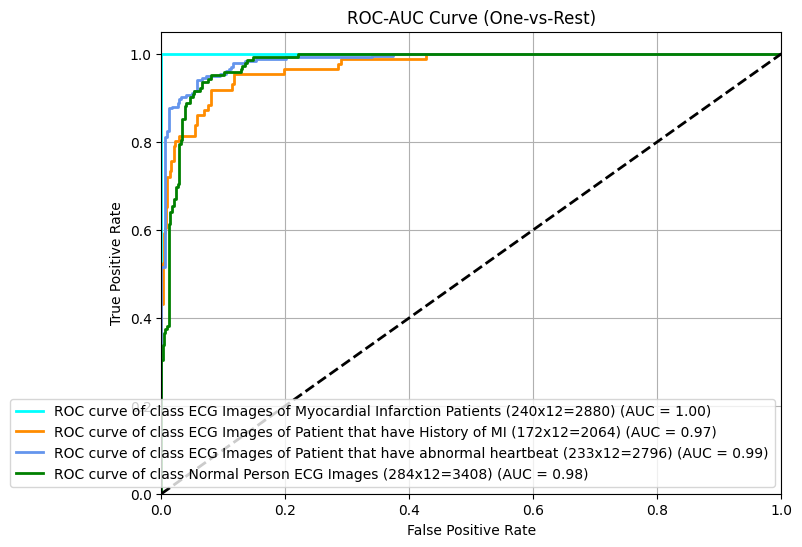

In [63]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
from itertools import cycle

# Fit the model

# Evaluate the model on the test set
test_loss, test_acc = best_model.evaluate(test_generator)
print(f"\nTest Accuracy: {test_acc:.4f}")

# Get class labels from the generator
class_labels = list(test_generator.class_indices.keys())
num_classes = len(class_labels)

# Reset test_generator to ensure consistent iteration
test_generator.reset()

# Get true labels and predictions
y_true = []
y_pred_prob = []
for i in range(test_generator.samples // test_generator.batch_size):
    batch_x, batch_y = next(test_generator)
    y_true.append(batch_y)
    y_pred_prob.append(best_model.predict(batch_x))

# Concatenate all batches
y_true = np.concatenate(y_true, axis=0)
y_pred_prob = np.concatenate(y_pred_prob, axis=0)

# Convert one-hot encoded labels to class indices
y_true_classes = np.argmax(y_true, axis=1)
y_pred_classes = np.argmax(y_pred_prob, axis=1)

# Compute Precision, Recall, and F1 Score (macro-averaged for multi-class)
precision = precision_score(y_true_classes, y_pred_classes, average='macro')
recall = recall_score(y_true_classes, y_pred_classes, average='macro')
f1 = f1_score(y_true_classes, y_pred_classes, average='macro')

print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1 Score (macro): {f1:.4f}")

# Compute Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
print("\nConfusion Matrix:")
print(cm)

# Compute TPR, TNR, FPR, FNR per class
def compute_rates(conf_matrix, num_classes):
    tpr = []
    tnr = []
    fpr = []
    fnr = []
    for i in range(num_classes):
        tp = conf_matrix[i, i]
        fn = np.sum(conf_matrix[i, :]) - tp
        fp = np.sum(conf_matrix[:, i]) - tp
        tn = np.sum(conf_matrix) - (tp + fn + fp)
        
        tpr_i = tp / (tp + fn) if (tp + fn) > 0 else 0
        tnr_i = tn / (tn + fp) if (tn + fp) > 0 else 0
        fpr_i = fp / (fp + tn) if (fp + tn) > 0 else 0
        fnr_i = fn / (fn + tp) if (fn + tp) > 0 else 0
        
        tpr.append(tpr_i)
        tnr.append(tnr_i)
        fpr.append(fpr_i)
        fnr.append(fnr_i)
    
    return tpr, tnr, fpr, fnr

tpr, tnr, fpr, fnr = compute_rates(cm, num_classes)
print("\nPer-class Metrics:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}':")
    print(f"  TPR (Recall): {tpr[i]:.4f}")
    print(f"  TNR: {tnr[i]:.4f}")
    print(f"  FPR: {fpr[i]:.4f}")
    print(f"  FNR: {fnr[i]:.4f}")

# Compute AUC for each class (One-vs-Rest)
fpr_roc = {}
tpr_roc = {}
roc_auc = {}
for i in range(num_classes):
    fpr_roc[i], tpr_roc[i], _ = roc_curve(y_true[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr_roc[i], tpr_roc[i])
print("\nAUC per class:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}': AUC = {roc_auc[i]:.4f}")

# Plot ROC-AUC Curve
plt.figure(figsize=(8, 6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple', 'brown', 'pink', 'gray', 'olive'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr_roc[i], tpr_roc[i], color=color, lw=2,
             label=f'ROC curve of class {class_labels[i]} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [64]:
test_loss, test_acc =best_model.evaluate(test_generator)
print(f"\nTest Accuracy: {test_acc}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 18s 620ms/step - accuracy: 0.9019 - loss: 0.3132

Test Accuracy: 0.8868534564971924


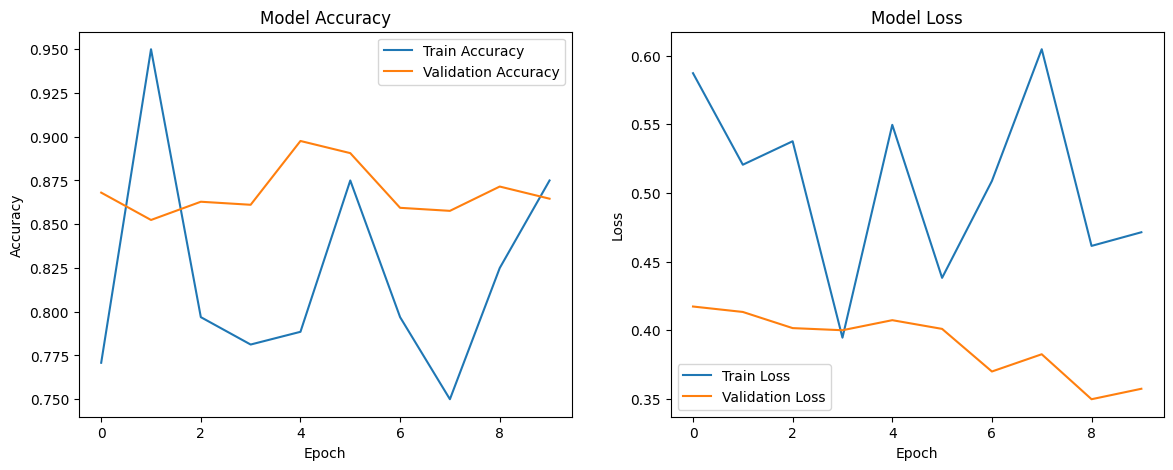

In [65]:
def plot_training_history(history):
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

plot_training_history(history)


AUC per class:
Class 'Myocardial Infarction (MI)': AUC = 1.0000
Class 'History of MI': AUC = 0.9716
Class 'Abnormal Heartbeat': AUC = 0.9858
Class 'Normal': AUC = 0.9784


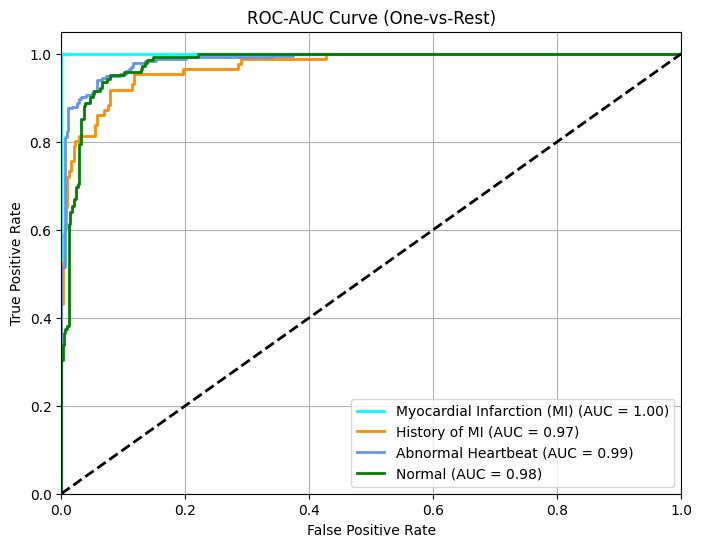

In [67]:
# Define shortened class labels
class_labels = ["Myocardial Infarction (MI)", "History of MI", "Abnormal Heartbeat", "Normal"]

# Compute AUC for each class (One-vs-Rest)
fpr_roc = {}
tpr_roc = {}
roc_auc = {}
for i in range(num_classes):
    fpr_roc[i], tpr_roc[i], _ = roc_curve(y_true[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr_roc[i], tpr_roc[i])

print("\nAUC per class:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}': AUC = {roc_auc[i]:.4f}")

# Plot ROC-AUC Curve
plt.figure(figsize=(8, 6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr_roc[i], tpr_roc[i], color=color, lw=2,
             label=f'{class_labels[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# **MobilenetV2**

In [21]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Load MobileNetV2 base model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze base model

# Build the model
model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(train_generator.class_indices), activation='softmax')  # use train_generator before this
])

# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


In [24]:
from tensorflow.keras import layers, models

#  **Hyperparameter tuning with Keras Tuner**

In [25]:
from kerastuner.tuners import RandomSearch
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf

# Image shape and batch size
IMG_SHAPE = (224, 224, 3)
BATCH_SIZE = 32

# Data preprocessing with validation split
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)



# Define model building function
def build_mobilenetv2_model(hp):
    base_model = MobileNetV2(
        include_top=False,
        input_shape=IMG_SHAPE,
        weights='imagenet'
    )
    base_model.trainable = False  # Freeze base layers

    model = models.Sequential()
    model.add(base_model)
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dropout(hp.Float('dropout', 0.2, 0.5, step=0.1)))
    model.add(layers.Dense(hp.Int('dense_units', 64, 256, step=64), activation='relu'))
    model.add(layers.Dense(len(train_generator.class_indices), activation='softmax'))

    model.compile(
        optimizer=optimizers.Adam(hp.Choice('learning_rate', [1e-2, 1e-3, 1e-4])),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Initialize tuner
tuner = RandomSearch(
    build_mobilenetv2_model,
    objective='val_accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='mobilenetv2_tuning',
    project_name='mobilenetv2_hyperparam'
)

# Run hyperparameter search
tuner.search(train_generator, validation_data=validation_generator, epochs=10)

# Get the best model
best_model = tuner.get_best_models(num_models=1)[0]


Trial 10 Complete [00h 09m 37s]
val_accuracy: 0.7877280116081238

Best val_accuracy So Far: 0.9320066571235657
Total elapsed time: 01h 38m 24s


/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [26]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [27]:
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 192)            │       245,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           772 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,504,708 (9.55 MB)

 Trainable params: 246,724 (963.77 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [28]:
history = best_model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    epochs=10  
)

Epoch 1/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 68s 793ms/step - accuracy: 0.8003 - loss: 0.5842 - val_accuracy: 0.9219 - val_loss: 0.2426
Epoch 2/10
 1/75 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.9062 - loss: 0.3399

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


75/75 ━━━━━━━━━━━━━━━━━━━━ 11s 150ms/step - accuracy: 0.9062 - loss: 0.3399 - val_accuracy: 0.9253 - val_loss: 0.2304
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 55s 734ms/step - accuracy: 0.8679 - loss: 0.3447 - val_accuracy: 0.9097 - val_loss: 0.2729
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 12s 156ms/step - accuracy: 0.9062 - loss: 0.2631 - val_accuracy: 0.8993 - val_loss: 0.2837
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 54s 715ms/step - accuracy: 0.8627 - loss: 0.3243 - val_accuracy: 0.9184 - val_loss: 0.2517
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 12s 156ms/step - accuracy: 0.8438 - loss: 0.6697 - val_accuracy: 0.9358 - val_loss: 0.1988
Epoch 7/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 55s 730ms/step - accuracy: 0.8779 - loss: 0.3156 - val_accuracy: 0.9358 - val_loss: 0.2049
Epoch 8/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 11s 149ms/step - accuracy: 0.9062 - loss: 0.2584 - val_accuracy: 0.9236 - val_loss: 0.2065
Epoch 9/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 56s 752ms/step - accuracy: 0.8386 - loss: 0.4404 - val_accuracy: 0.859

29/29 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.8723 - loss: 0.2717

Test Accuracy: 0.8750
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms

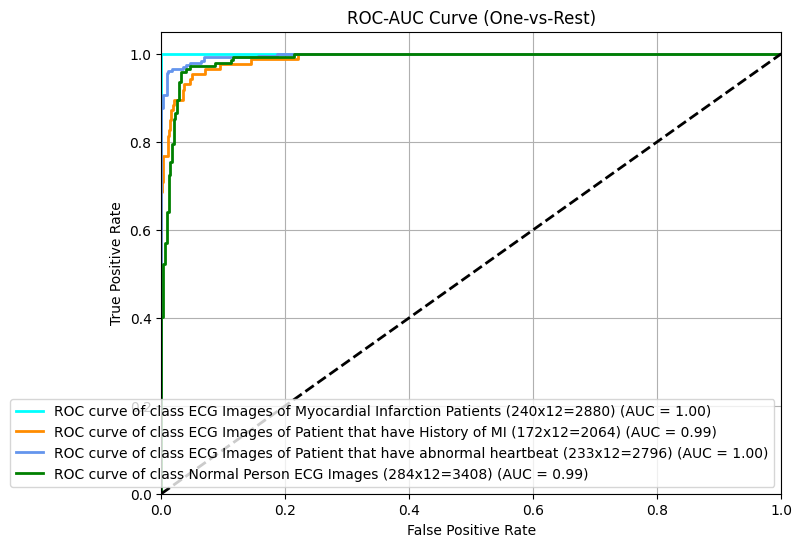

In [29]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
from itertools import cycle

# Fit the model

# Evaluate the model on the test set
test_loss, test_acc = best_model.evaluate(test_generator)
print(f"\nTest Accuracy: {test_acc:.4f}")

# Get class labels from the generator
class_labels = list(test_generator.class_indices.keys())
num_classes = len(class_labels)

# Reset test_generator to ensure consistent iteration
test_generator.reset()

# Get true labels and predictions
y_true = []
y_pred_prob = []
for i in range(test_generator.samples // test_generator.batch_size):
    batch_x, batch_y = next(test_generator)
    y_true.append(batch_y)
    y_pred_prob.append(best_model.predict(batch_x))

# Concatenate all batches
y_true = np.concatenate(y_true, axis=0)
y_pred_prob = np.concatenate(y_pred_prob, axis=0)

# Convert one-hot encoded labels to class indices
y_true_classes = np.argmax(y_true, axis=1)
y_pred_classes = np.argmax(y_pred_prob, axis=1)

# Compute Precision, Recall, and F1 Score (macro-averaged for multi-class)
precision = precision_score(y_true_classes, y_pred_classes, average='macro')
recall = recall_score(y_true_classes, y_pred_classes, average='macro')
f1 = f1_score(y_true_classes, y_pred_classes, average='macro')

print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1 Score (macro): {f1:.4f}")

# Compute Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
print("\nConfusion Matrix:")
print(cm)

# Compute TPR, TNR, FPR, FNR per class
def compute_rates(conf_matrix, num_classes):
    tpr = []
    tnr = []
    fpr = []
    fnr = []
    for i in range(num_classes):
        tp = conf_matrix[i, i]
        fn = np.sum(conf_matrix[i, :]) - tp
        fp = np.sum(conf_matrix[:, i]) - tp
        tn = np.sum(conf_matrix) - (tp + fn + fp)
        
        tpr_i = tp / (tp + fn) if (tp + fn) > 0 else 0
        tnr_i = tn / (tn + fp) if (tn + fp) > 0 else 0
        fpr_i = fp / (fp + tn) if (fp + tn) > 0 else 0
        fnr_i = fn / (fn + tp) if (fn + tp) > 0 else 0
        
        tpr.append(tpr_i)
        tnr.append(tnr_i)
        fpr.append(fpr_i)
        fnr.append(fnr_i)
    
    return tpr, tnr, fpr, fnr

tpr, tnr, fpr, fnr = compute_rates(cm, num_classes)
print("\nPer-class Metrics:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}':")
    print(f"  TPR (Recall): {tpr[i]:.4f}")
    print(f"  TNR: {tnr[i]:.4f}")
    print(f"  FPR: {fpr[i]:.4f}")
    print(f"  FNR: {fnr[i]:.4f}")

# Compute AUC for each class (One-vs-Rest)
fpr_roc = {}
tpr_roc = {}
roc_auc = {}
for i in range(num_classes):
    fpr_roc[i], tpr_roc[i], _ = roc_curve(y_true[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr_roc[i], tpr_roc[i])
print("\nAUC per class:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}': AUC = {roc_auc[i]:.4f}")

# Plot ROC-AUC Curve
plt.figure(figsize=(8, 6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple', 'brown', 'pink', 'gray', 'olive'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr_roc[i], tpr_roc[i], color=color, lw=2,
             label=f'ROC curve of class {class_labels[i]} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [32]:
test_loss, test_acc =best_model.evaluate(test_generator)
print(f"\nTest Accuracy: {test_acc}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 17s 583ms/step - accuracy: 0.8736 - loss: 0.2728

Test Accuracy: 0.875


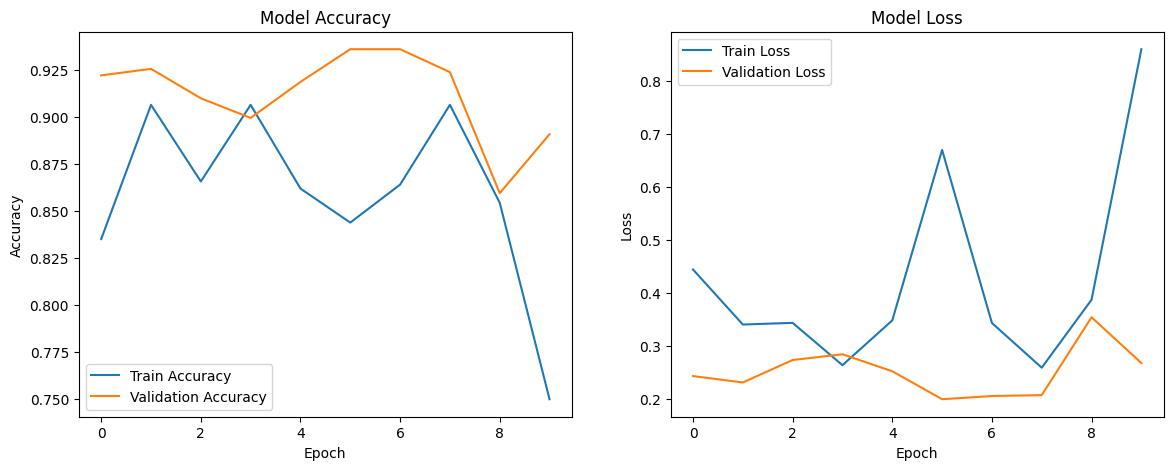

In [33]:
def plot_training_history(history):
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

plot_training_history(history)


AUC per class:
Class 'Myocardial Infarction (MI)': AUC = 1.0000
Class 'History of MI': AUC = 0.9895
Class 'Abnormal Heartbeat': AUC = 0.9965
Class 'Normal': AUC = 0.9882


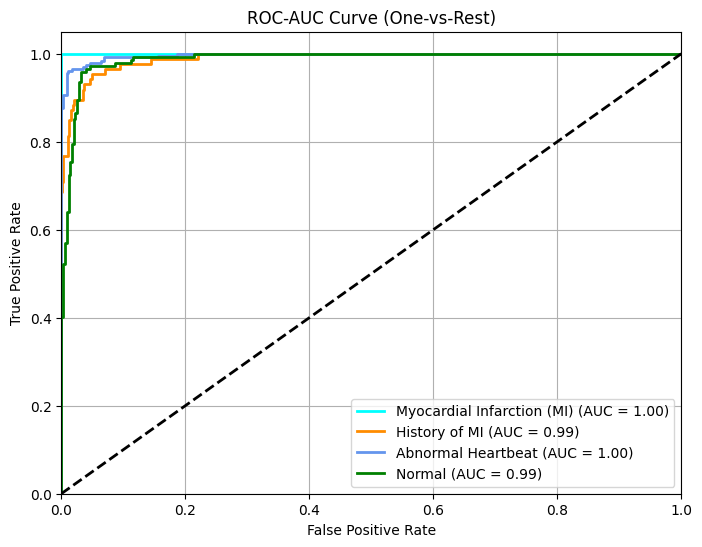

In [34]:
# Define shortened class labels
class_labels = ["Myocardial Infarction (MI)", "History of MI", "Abnormal Heartbeat", "Normal"]

# Compute AUC for each class (One-vs-Rest)
fpr_roc = {}
tpr_roc = {}
roc_auc = {}
for i in range(num_classes):
    fpr_roc[i], tpr_roc[i], _ = roc_curve(y_true[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr_roc[i], tpr_roc[i])

print("\nAUC per class:")
for i, label in enumerate(class_labels):
    print(f"Class '{label}': AUC = {roc_auc[i]:.4f}")

# Plot ROC-AUC Curve
plt.figure(figsize=(8, 6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr_roc[i], tpr_roc[i], color=color, lw=2,
             label=f'{class_labels[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()